In [2]:
import pandas as pd

In [ ]:
# Simple Linear Regression vs Multiple Linear Regression

## Objective

This notebook compares Simple Linear Regression (SLR) and Multiple Linear Regression (MLR).

We will:

1. Load a dataset containing 5,000 observations.
2. Use one feature for Simple Linear Regression.
3. Use four features for Multiple Linear Regression.
4. Split the data into training and testing sets.
5. Evaluate both models using MSE, MAE, and R².
6. Visualize predictions and residuals.


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Libraries imported successfully!")

In [1]:
df = pd.read_csv("regression_data.csv")

print("Dataset shape:", df.shape)
display(df.head())

NameError: name 'pd' is not defined

In [3]:
df = pd.read_csv("regression_data.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (5000, 5)


,feature_1,feature_2,feature_3,feature_4,target
0,53.047171,18.710240,78.144831,-0.558842,335.293854
1,39.600159,18.502571,24.933685,0.764901,372.198814
2,57.504512,16.516700,82.084138,0.828076,406.507076
3,59.405647,22.142415,17.713355,1.783857,526.578685
4,30.489648,21.173231,35.947352,-0.603630,261.868919


In [4]:
print("Dataset information:")
print(df.info())

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   feature_1  5000 non-null   float64
 1   feature_2  5000 non-null   float64
 2   feature_3  5000 non-null   float64
 3   feature_4  5000 non-null   float64
 4   target     5000 non-null   float64
dtypes: float64(5)
memory usage: 195.4 KB
None

Missing values in each column:
feature_1    0
feature_2    0
feature_3    0
feature_4    0
target       0
dtype: int64

Statistical summary:


,feature_1,feature_2,feature_3,feature_4,target
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,49.801230,19.996886,50.274743,0.039188,378.848711
std,9.994545,5.065897,28.536521,1.004738,99.251252
min,13.515872,-1.945573,0.012491,-3.700092,43.282324
25%,43.080460,16.691754,25.321907,-0.652490,311.383199
50%,49.958390,19.899721,50.610239,0.031177,379.436724
75%,56.312474,23.361493,75.075876,0.726126,447.335469
max,84.540464,40.129120,99.994726,3.200243,694.642456


In [5]:
# Simple Linear Regression: one input feature
X_simple = df[["feature_1"]]

# Multiple Linear Regression: four input features
X_multiple = df[
    ["feature_1", "feature_2", "feature_3", "feature_4"]
]

# Target variable
y = df["target"]

print("Simple model input shape:", X_simple.shape)
print("Multiple model input shape:", X_multiple.shape)
print("Target shape:", y.shape)

Simple model input shape: (5000, 1)
Multiple model input shape: (5000, 4)
Target shape: (5000,)


In [6]:
from sklearn.model_selection import train_test_split

# Split data for Simple Linear Regression
X_simple_train, X_simple_test, y_simple_train, y_simple_test = train_test_split(
    X_simple,
    y,
    test_size=0.2,
    random_state=42
)

# Split data for Multiple Linear Regression
X_multiple_train, X_multiple_test, y_multiple_train, y_multiple_test = train_test_split(
    X_multiple,
    y,
    test_size=0.2,
    random_state=42
)

print("SIMPLE LINEAR REGRESSION")
print("Training features:", X_simple_train.shape)
print("Testing features:", X_simple_test.shape)

print("\nMULTIPLE LINEAR REGRESSION")
print("Training features:", X_multiple_train.shape)
print("Testing features:", X_multiple_test.shape)

print("\nTARGET DATA")
print("Training targets:", y_simple_train.shape)
print("Testing targets:", y_simple_test.shape)

SIMPLE LINEAR REGRESSION
Training features: (4000, 1)
Testing features: (1000, 1)

MULTIPLE LINEAR REGRESSION
Training features: (4000, 4)
Testing features: (1000, 4)

TARGET DATA
Training targets: (4000,)
Testing targets: (1000,)


In [8]:
# Import the regression model
from sklearn.linear_model import LinearRegression

# Create the Simple Linear Regression model
simple_model = LinearRegression()

# Train the Simple Linear Regression model
simple_model.fit(X_simple_train, y_simple_train)

# Create the Multiple Linear Regression model
multiple_model = LinearRegression()

# Train the Multiple Linear Regression model
multiple_model.fit(X_multiple_train, y_multiple_train)

print("Both regression models trained successfully!")

Both regression models trained successfully!


In [9]:
# Make predictions using the Simple Linear Regression model
y_simple_pred = simple_model.predict(X_simple_test)

# Make predictions using the Multiple Linear Regression model
y_multiple_pred = multiple_model.predict(X_multiple_test)

print("Simple Linear Regression predictions:")
print(y_simple_pred[:5])

print("\nMultiple Linear Regression predictions:")
print(y_multiple_pred[:5])

Simple Linear Regression predictions:
[330.63114372 386.93148108 314.53627428 497.51463436 302.66447663]

Multiple Linear Regression predictions:
[281.23316184 449.32495416 367.60104467 555.8987287  213.86397997]


In [10]:
# Make predictions using Simple Linear Regression
y_simple_pred = simple_model.predict(X_simple_test)

# Make predictions using Multiple Linear Regression
y_multiple_pred = multiple_model.predict(X_multiple_test)

print("First 5 predictions — Simple Linear Regression:")
print(y_simple_pred[:5])

print("\nFirst 5 predictions — Multiple Linear Regression:")
print(y_multiple_pred[:5])

First 5 predictions — Simple Linear Regression:
[330.63114372 386.93148108 314.53627428 497.51463436 302.66447663]

First 5 predictions — Multiple Linear Regression:
[281.23316184 449.32495416 367.60104467 555.8987287  213.86397997]


In [11]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Evaluate Simple Linear Regression
simple_mse = mean_squared_error(y_simple_test, y_simple_pred)
simple_mae = mean_absolute_error(y_simple_test, y_simple_pred)
simple_r2 = r2_score(y_simple_test, y_simple_pred)

# Evaluate Multiple Linear Regression
multiple_mse = mean_squared_error(y_multiple_test, y_multiple_pred)
multiple_mae = mean_absolute_error(y_multiple_test, y_multiple_pred)
multiple_r2 = r2_score(y_multiple_test, y_multiple_pred)

# Display results
print("SIMPLE LINEAR REGRESSION")
print(f"MSE: {simple_mse:.2f}")
print(f"MAE: {simple_mae:.2f}")
print(f"R²:  {simple_r2:.4f}")

print("\nMULTIPLE LINEAR REGRESSION")
print(f"MSE: {multiple_mse:.2f}")
print(f"MAE: {multiple_mae:.2f}")
print(f"R²:  {multiple_r2:.4f}")

SIMPLE LINEAR REGRESSION
MSE: 3546.59
MAE: 49.39
R²:  0.6630

MULTIPLE LINEAR REGRESSION
MSE: 131.35
MAE: 9.19
R²:  0.9875


In [12]:
comparison = pd.DataFrame({
    "Model": [
        "Simple Linear Regression",
        "Multiple Linear Regression"
    ],
    "MSE": [simple_mse, multiple_mse],
    "MAE": [simple_mae, multiple_mae],
    "R2 Score": [simple_r2, multiple_r2]
})

display(comparison.round(4))

,Model,MSE,MAE,R2 Score
0,Simple Linear Regression,3546.5946,49.3902,0.6630
1,Multiple Linear Regression,131.3473,9.1862,0.9875


In [13]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Predictions from both trained models
y_simple_pred = simple_model.predict(X_simple_test)
y_multiple_pred = multiple_model.predict(X_multiple_test)

# Calculate metrics for Simple Linear Regression
simple_mse = mean_squared_error(y_simple_test, y_simple_pred)
simple_mae = mean_absolute_error(y_simple_test, y_simple_pred)
simple_r2 = r2_score(y_simple_test, y_simple_pred)

# Calculate metrics for Multiple Linear Regression
multiple_mse = mean_squared_error(y_multiple_test, y_multiple_pred)
multiple_mae = mean_absolute_error(y_multiple_test, y_multiple_pred)
multiple_r2 = r2_score(y_multiple_test, y_multiple_pred)

# Display results
comparison = pd.DataFrame({
    "Model": [
        "Simple Linear Regression",
        "Multiple Linear Regression"
    ],
    "MSE": [simple_mse, multiple_mse],
    "MAE": [simple_mae, multiple_mae],
    "R2 Score": [simple_r2, multiple_r2]
})

display(comparison.round(4))

,Model,MSE,MAE,R2 Score
0,Simple Linear Regression,3546.5946,49.3902,0.6630
1,Multiple Linear Regression,131.3473,9.1862,0.9875


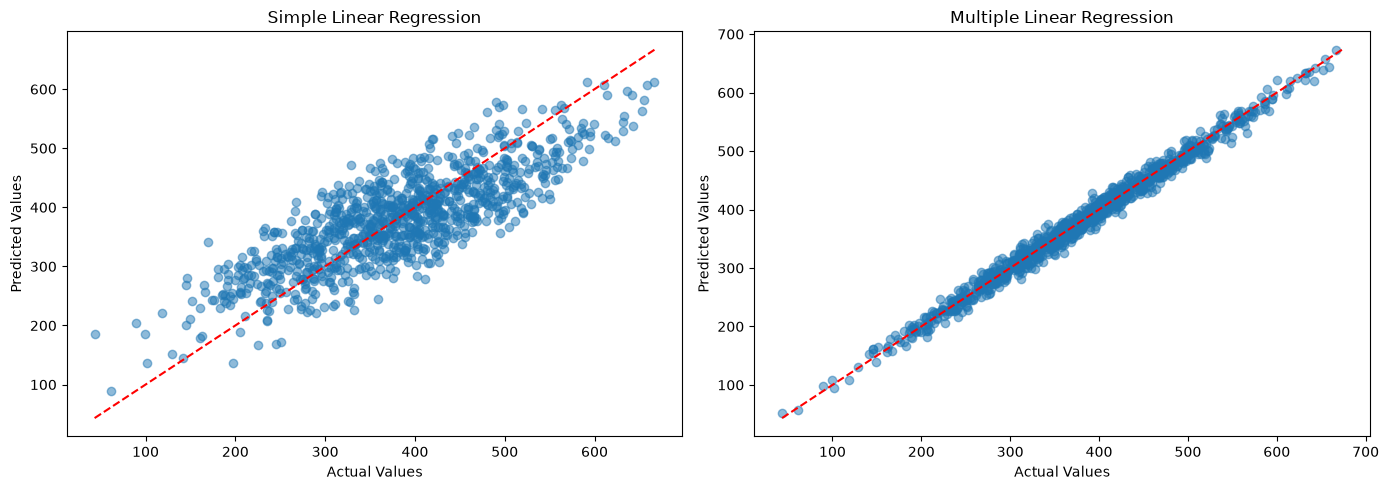

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Simple Linear Regression
axes[0].scatter(y_simple_test, y_simple_pred, alpha=0.5)
axes[0].set_title("Simple Linear Regression")
axes[0].set_xlabel("Actual Values")
axes[0].set_ylabel("Predicted Values")

# Multiple Linear Regression
axes[1].scatter(y_multiple_test, y_multiple_pred, alpha=0.5)
axes[1].set_title("Multiple Linear Regression")
axes[1].set_xlabel("Actual Values")
axes[1].set_ylabel("Predicted Values")

# Add ideal prediction lines
simple_min = min(y_simple_test.min(), y_simple_pred.min())
simple_max = max(y_simple_test.max(), y_simple_pred.max())

multiple_min = min(y_multiple_test.min(), y_multiple_pred.min())
multiple_max = max(y_multiple_test.max(), y_multiple_pred.max())

axes[0].plot([simple_min, simple_max], [simple_min, simple_max], "r--")
axes[1].plot(
    [multiple_min, multiple_max],
    [multiple_min, multiple_max],
    "r--"
)

plt.tight_layout()
plt.show()

In [15]:
import matplotlib.pyplot as plt

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


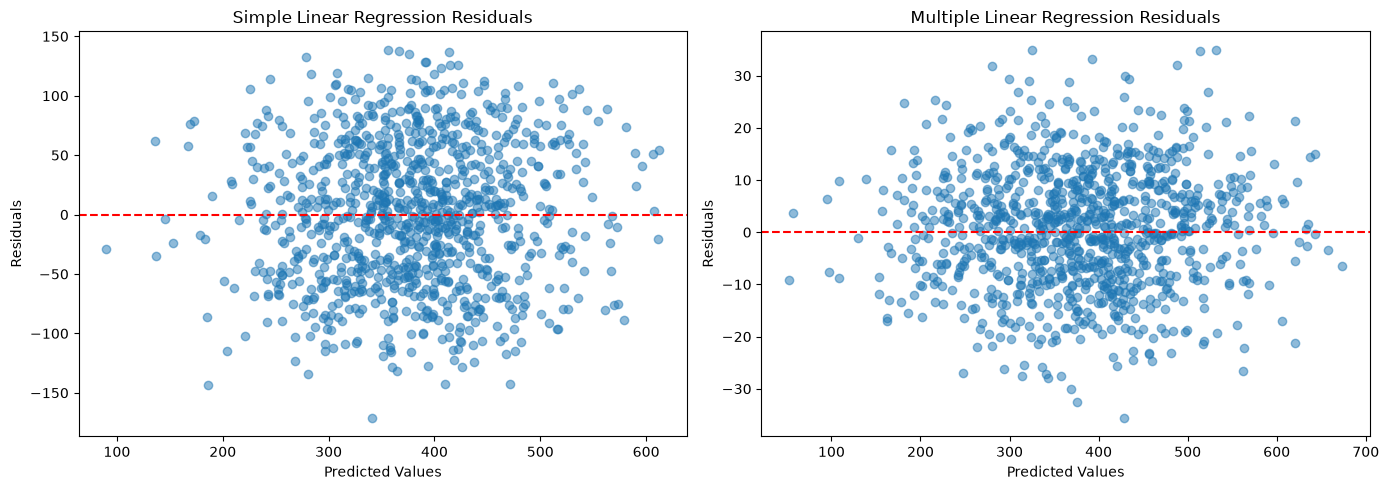

In [18]:
# Calculate residuals for both models
simple_residuals = y_simple_test - y_simple_pred
multiple_residuals = y_multiple_test - y_multiple_pred

# Create two residual plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Simple Linear Regression
axes[0].scatter(y_simple_pred, simple_residuals, alpha=0.5)
axes[0].axhline(y=0, color="red", linestyle="--")
axes[0].set_title("Simple Linear Regression Residuals")
axes[0].set_xlabel("Predicted Values")
axes[0].set_ylabel("Residuals")

# Multiple Linear Regression
axes[1].scatter(y_multiple_pred, multiple_residuals, alpha=0.5)
axes[1].axhline(y=0, color="red", linestyle="--")
axes[1].set_title("Multiple Linear Regression Residuals")
axes[1].set_xlabel("Predicted Values")
axes[1].set_ylabel("Residuals")

plt.tight_layout()
plt.show()